# 03 · Settlement exposure

Built-up land = ESA WorldCover 2021 class 50 (10 m). **Direct overlap is close to zero by construction**: SAR cannot detect water among buildings (double-bounce keeps built-up pixels bright), so the flood mask almost never falls on built-up pixels. Exposure is therefore measured as built-up land **within a distance of mapped flood water** — 50 m (main), with 30 m and 100 m as sensitivity. This indicates spatial proximity to inundation, not confirmed damage or affected population.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, geopandas as gpd, rasterio, matplotlib.pyplot as plt
from scipy import ndimage
from shapely.geometry import box
import config, classify as C

st = C.static()
district = st["district"]
built = (st["worldcover"] == 50) & district
DISTANCES_M = [0, 30, 50, 100]
MAIN_M = 50
print("built-up in district:", round(built.sum() * C.PIX_KM2, 1), "km2",
      f"({100 * built.sum() / district.sum():.1f} % of district)")

maps = {}
for date, orb in config.EVENT_DATES:
    with rasterio.open(config.OUT_RASTERS / f"flood_{date.replace('-', '')}_t{orb}.tif") as r:
        maps[(date, orb)] = r.read(1)

built-up in district: 63.9 km2 (2.5 % of district)


## Flood frequency and union of all dates

`any_flood` = flooded on at least one June date. `freq` = number of dates flooded.

In [2]:
freq = np.zeros(district.shape, np.uint8)
obs = np.zeros(district.shape, np.uint8)
for cl in maps.values():
    freq += (cl == 1); obs += (cl != 255)
any_flood = freq > 0
p = C.profile() | {"count": 2, "dtype": "uint8", "nodata": 255, "compress": "deflate"}
with rasterio.open(config.OUT_RASTERS / "flood_frequency_june2022.tif", "w", **p) as dst:
    dst.write(np.where(district, freq, 255), 1); dst.write(np.where(district, obs, 255), 2)
    dst.descriptions = ("dates_flooded", "dates_observed")
print("flooded on >=1 date:", round(any_flood.sum() * C.PIX_KM2, 1), "km2;",
      "on >=3 dates:", round((freq >= 3).sum() * C.PIX_KM2, 1), "km2")

flooded on >=1 date: 766.4 km2; on >=3 dates: 405.4 km2


## Exposure by date

In [3]:
def dist_to_flood_m(flood):
    """Euclidean distance (m) from every pixel to the nearest flood pixel."""
    return (ndimage.distance_transform_edt(~flood) * 10).astype(np.float32)

# settlement clusters = 8-connected patches of built-up pixels
clusters, n_clusters = ndimage.label(built, structure=np.ones((3, 3), bool))
print("built-up clusters in district:", n_clusters)

def exposure_row(flood, observed, label):
    d = dist_to_flood_m(flood)
    b_obs = built & observed
    row = {"scenario": label, "built_observed_km2": b_obs.sum() * C.PIX_KM2}
    for m in DISTANCES_M:
        e = b_obs & (d <= m) if m else b_obs & flood
        row[f"exposed_{m}m_km2"] = e.sum() * C.PIX_KM2
        row[f"exposed_{m}m_pct"] = 100 * e.sum() / max(b_obs.sum(), 1)
    hit = np.unique(clusters[b_obs & (d <= MAIN_M)]); hit = hit[hit > 0]
    row[f"clusters_within_{MAIN_M}m"] = len(hit)
    return row, d

rows, dist = [], {}
for (date, orb), cl in maps.items():
    r, d = exposure_row(cl == 1, cl != 255, f"{date} t{orb}")
    rows.append(r); dist[(date, orb)] = d
r, d_any = exposure_row(any_flood, obs > 0, "any June date")
rows.append(r)
expo = pd.DataFrame(rows).round(2)
expo.to_csv(config.OUT_TABLES / "exposure_by_date.csv", index=False)
expo

built-up clusters in district: 29799


,scenario,built_observed_km2,exposed_0m_km2,exposed_0m_pct,exposed_30m_km2,exposed_30m_pct,exposed_50m_km2,exposed_50m_pct,exposed_100m_km2,exposed_100m_pct,clusters_within_50m
0,2022-06-04 t41,63.36,0.01,0.01,0.23,0.36,0.79,1.25,3.03,4.78,1011
1,2022-06-06 t77,63.95,0.01,0.02,0.32,0.49,1.00,1.56,3.79,5.93,1224
2,2022-06-16 t41,63.37,0.01,0.01,0.49,0.78,2.02,3.18,8.63,13.61,2921
3,2022-06-18 t77,63.95,0.06,0.09,1.21,1.90,3.60,5.62,12.19,19.06,4726
4,2022-06-28 t41,63.37,0.06,0.09,1.43,2.25,4.49,7.08,16.02,25.29,5826
5,2022-06-30 t77,63.95,0.03,0.05,1.35,2.12,4.61,7.20,17.15,26.81,6248
6,any June date,63.95,0.14,0.22,2.61,4.08,7.24,11.32,22.30,34.87,8806


## Exposure by sub-district (main 50 m distance)

In [4]:
subs = gpd.read_file(config.DATA_PROCESSED / "nagaon_2022_subdistricts.geojson").reset_index(drop=True)
sub_id = C.rasterize_gdf(subs, values=range(1, len(subs) + 1))
n = len(subs) + 1
recs = []
scen = list(dist.items()) + [(("any", "June"), d_any)]
for (date, orb), d in scen:
    observed = (maps[(date, orb)] != 255) if date != "any" else (obs > 0)
    b_obs = built & observed
    tot = np.bincount(sub_id[b_obs], minlength=n) * C.PIX_KM2
    exp = np.bincount(sub_id[b_obs & (d <= MAIN_M)], minlength=n) * C.PIX_KM2
    for i, name in enumerate(subs["sdtname"], start=1):
        recs.append({"scenario": f"{date} t{orb}" if date != "any" else "any June date",
                     "subdistrict": name, "built_km2": tot[i], "exposed_km2": exp[i],
                     "exposed_pct": 100 * exp[i] / tot[i] if tot[i] else np.nan})
by_sub = pd.DataFrame(recs).round(2)
by_sub.to_csv(config.OUT_TABLES / "exposure_by_subdistrict.csv", index=False)
by_sub.pivot(index="subdistrict", columns="scenario", values="exposed_km2")

scenario,2022-06-04 t41,2022-06-06 t77,2022-06-16 t41,2022-06-18 t77,2022-06-28 t41,2022-06-30 t77,any June date
subdistrict,,,,,,,
Dhing,0.04,0.10,0.31,0.39,0.51,0.59,1.04
Kaliabor,0.04,0.07,0.13,0.17,0.19,0.27,0.42
Kampur,0.16,0.19,0.26,0.71,0.43,0.37,0.81
Nagaon,0.22,0.24,0.43,0.62,1.11,1.09,1.64
Raha,0.29,0.29,0.47,1.01,1.19,1.01,1.47
Rupahi,0.02,0.07,0.22,0.42,0.61,0.71,1.10
Samaguri,0.02,0.04,0.19,0.28,0.45,0.56,0.77


In [5]:
by_sub[by_sub.scenario == "any June date"].sort_values("exposed_km2", ascending=False)

,scenario,subdistrict,built_km2,exposed_km2,exposed_pct
46,any June date,Nagaon,21.26,1.64,7.70
47,any June date,Raha,5.88,1.47,25.06
44,any June date,Rupahi,9.35,1.10,11.73
45,any June date,Dhing,8.84,1.04,11.75
48,any June date,Kampur,3.56,0.81,22.69
43,any June date,Samaguri,7.49,0.77,10.23
42,any June date,Kaliabor,7.57,0.42,5.53


## 1 km grid summary (for mapping where exposure concentrates)

In [6]:
prof = C.profile(); t = prof["transform"]; H, W = prof["height"], prof["width"]
k = 100  # 100 x 10 m = 1 km cells
Hc, Wc = H // k, W // k
def block_sum(a):
    return a[:Hc * k, :Wc * k].reshape(Hc, k, Wc, k).sum(axis=(1, 3)) * C.PIX_KM2

exp_any = block_sum(built & (obs > 0) & (d_any <= MAIN_M))
built_c = block_sum(built)
peak = ("2022-06-30", 77)
exp_peak = block_sum(built & (maps[peak] != 255) & (dist[peak] <= MAIN_M))
flood_any_c = block_sum(any_flood)
cells = []
for i in range(Hc):
    for j in range(Wc):
        x0 = t.c + j * k * t.a; y1 = t.f + i * k * t.e
        cells.append(box(x0, y1 + k * t.e, x0 + k * t.a, y1))
grid = gpd.GeoDataFrame({"built_km2": built_c.ravel(), "exposed_any_km2": exp_any.ravel(),
                         "exposed_30jun_km2": exp_peak.ravel(), "flood_any_km2": flood_any_c.ravel()},
                        geometry=cells, crs=prof["crs"])
dist_poly = gpd.read_file(config.BOUNDARY_FILE).to_crs(prof["crs"])
grid = grid[grid.intersects(dist_poly.geometry.iloc[0])].reset_index(drop=True)
grid["exposed_any_pct"] = np.where(grid.built_km2 > 0, 100 * grid.exposed_any_km2 / grid.built_km2, np.nan)
gpkg = config.DATA_PROCESSED / "exposure_grid_1km.gpkg"
grid.to_file(gpkg, layer="exposure_grid_1km", driver="GPKG")
print(len(grid), "cells written to", gpkg.name)

2910 cells written to exposure_grid_1km.gpkg


## Exposure raster and map

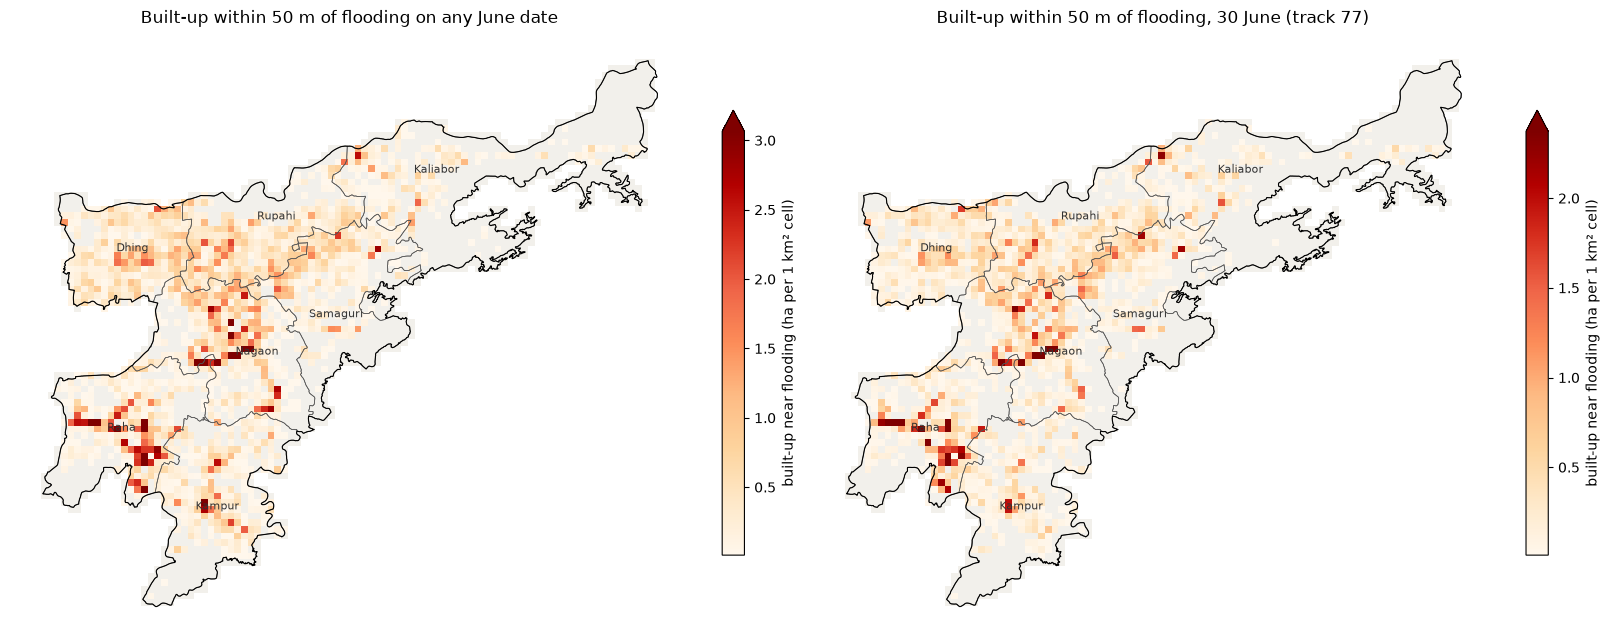

In [7]:
# 0 = not built-up, 1 = built-up not exposed, 2 = built-up 50-100 m from flood, 3 = built-up <= 50 m
ex_cls = np.zeros(district.shape, np.uint8)
ex_cls[built] = 1
ex_cls[built & (d_any <= 100)] = 2
ex_cls[built & (d_any <= MAIN_M)] = 3
ex_cls[~district] = 255
p1 = C.profile() | {"count": 1, "dtype": "uint8", "nodata": 255, "compress": "deflate"}
with rasterio.open(config.OUT_RASTERS / "exposure_any_june2022.tif", "w", **p1) as dst:
    dst.write(ex_cls, 1); dst.descriptions = ("0 other, 1 built not exposed, 2 built 50-100 m, 3 built <=50 m",)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), constrained_layout=True)
for ax, col, title in [(axes[0], "exposed_any_km2", "Built-up within 50 m of flooding on any June date"),
                       (axes[1], "exposed_30jun_km2", "Built-up within 50 m of flooding, 30 June (track 77)")]:
    g = grid[grid[col] > 0].assign(ha=lambda x: x[col] * 100)
    grid.plot(ax=ax, color="#f2f0eb", linewidth=0)
    g.plot(ax=ax, column="ha", cmap="OrRd", linewidth=0, legend=True,
           legend_kwds={"label": "built-up near flooding (ha per 1 km² cell)", "shrink": 0.6},
           vmax=g["ha"].quantile(0.99))
    subs.to_crs(prof["crs"]).boundary.plot(ax=ax, color="#555", lw=0.5)
    dist_poly.boundary.plot(ax=ax, color="k", lw=0.8)
    for _, s in subs.to_crs(prof["crs"]).iterrows():
        c = s.geometry.representative_point(); ax.annotate(s.sdtname, (c.x, c.y), ha="center", fontsize=8, color="#333")
    ax.set_title(title); ax.set_axis_off()
fig.savefig(config.OUT_FIGURES / "exposure_grid_1km.png", dpi=150)
plt.show()

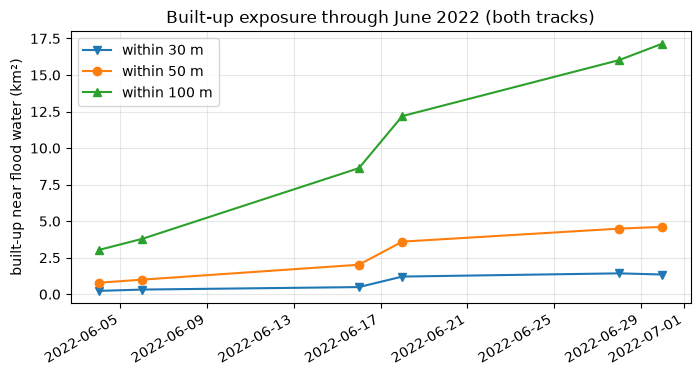

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
e = expo[expo.scenario != "any June date"].copy()
e["date"] = pd.to_datetime(e.scenario.str[:10])
for m, mk in [(30, "v"), (50, "o"), (100, "^")]:
    ax.plot(e.date, e[f"exposed_{m}m_km2"], mk + "-", label=f"within {m} m")
ax.set_ylabel("built-up near flood water (km²)"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Built-up exposure through June 2022 (both tracks)")
fig.autofmt_xdate(); fig.savefig(config.OUT_FIGURES / "exposure_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()